In [1]:
import os
import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score, confusion_matrix, classification_report
from pathlib import Path

In [61]:
SR = 22050
rows = []

for i, f in enumerate(Path("data/messy_mashup/genres_stems").rglob("*.wav")):
    if i % 100 == 0:
        print(i)

    genre = str(f).split("/")[3]
    stem = f.name
    duration = librosa.get_duration(path=f)
    y, _ = librosa.load(f)

    peak_linear = np.max(np.abs(y + 1e-8))
    peak_db = 20 * np.log10(peak_linear)

    centroid = librosa.feature.spectral_centroid(y=y)
    centroid_mean = np.mean(centroid)

    n = int(SR * 0.5)
    seg = y[:n]
    rms = np.sqrt(np.mean(seg**2))
    rms_db = 20 * np.log10(rms + 1e-8)

    rows.append({"file": f, "genre": str(genre), "stem": stem, "duration": duration, "peak": peak_db, "centroid": centroid_mean, "start": rms_db})

df = pd.DataFrame(rows)

0
100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400
1500
1600
1700
1800
1900
2000
2100
2200
2300
2400
2500
2600
2700
2800
2900
3000
3100
3200
3300
3400
3500
3600
3700
3800
3900


In [62]:
df.loc[df["genre"] == "jazz", "duration"].mean()

np.float64(30.032979591836728)

In [63]:
df.loc[df["stem"] == "vocals.wav", "peak"].mean()

np.float32(-12.607831)

In [64]:
df.loc[df["genre"] == "blues", "centroid"].mean()

np.float64(2067.555785602781)

In [65]:
df.groupby(["genre"])["centroid"].mean().sort_values(ascending=False)

genre
metal        2498.200892
disco        2363.816616
pop          2357.604978
jazz         2269.444160
reggae       2260.420653
hiphop       2246.116420
rock         2150.968336
country      2101.189305
blues        2067.555786
classical    1410.770619
Name: centroid, dtype: float64

In [ ]:
df.loc[df["start"] < -60].shape # I'm taking the silence threshold as -60 dB here

(758, 7)

In [48]:
# --- 1. Setup and Preprocessing ---
ROOT = 'data/messy_mashup'
STEMS_PATH = os.path.join(ROOT, 'genres_stems')
GENRES = ["blues", "classical", "country", "disco", "hiphop", "jazz", "metal", "pop", "reggae", "rock"]

def extract_features(song_path):
    # Load 10s at 22050Hz
    y, sr = librosa.load(os.path.join(song_path, 'other.wav'), sr=22050, duration=10)
    tempo, _ = librosa.beat.beat_track(y=y, sr=sr)
    spec_cent = np.mean(librosa.feature.spectral_centroid(y=y, sr=sr))
    zcr = np.mean(librosa.feature.zero_crossing_rate(y))
    rolloff = np.mean(librosa.feature.spectral_rolloff(y=y, sr=sr))
    return [float(tempo), spec_cent, zcr, rolloff]

# --- 2. Data Preparation & Stratified Split ---
data = []
for g in GENRES:
    gp = os.path.join(STEMS_PATH, g)
    songs = [s for s in os.listdir(gp) if os.path.isdir(os.path.join(gp, s))]
    for s in songs[:50]: # Sampling 50 for speed; use all for final
        data.append({'path': os.path.join(gp, s), 'genre': g})

df = pd.DataFrame(data)
train_df, val_df = train_test_split(df, test_size=0.2, stratify=df['genre'], random_state=42)

# --- 3. Model Training (Decision Tree) ---
X_train = np.array([extract_features(p) for p in train_df['path']])
y_train = train_df['genre']
X_val = np.array([extract_features(p) for p in val_df['path']])
y_val = val_df['genre']

clf = DecisionTreeClassifier(max_depth=5, random_state=42)
clf.fit(X_train, y_train)

/tmp/ipykernel_3331/2118750574.py:13: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  return [float(tempo), spec_cent, zcr, rolloff]


,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current no

In [53]:
y_pred = clf.predict(X_val)
macro_f1 = f1_score(y_val, y_pred, average="macro")
cm = confusion_matrix(y_val, y_pred)
cr = classification_report(y_val, y_pred)

In [54]:
print(f"Validation Macro F1 Score: {macro_f1:.4f}\n")
print("Detailed Classification Report:")
print(cr)

Validation Macro F1 Score: 0.1878

Detailed Classification Report:
              precision    recall  f1-score   support

       blues       0.50      0.10      0.17        10
   classical       0.00      0.00      0.00        10
     country       0.00      0.00      0.00        10
       disco       0.14      0.10      0.12        10
      hiphop       0.43      0.30      0.35        10
        jazz       0.09      0.20      0.12        10
       metal       0.50      0.30      0.38        10
         pop       0.24      0.50      0.32        10
      reggae       0.18      0.30      0.22        10
        rock       0.20      0.20      0.20        10

    accuracy                           0.20       100
   macro avg       0.23      0.20      0.19       100
weighted avg       0.23      0.20      0.19       100



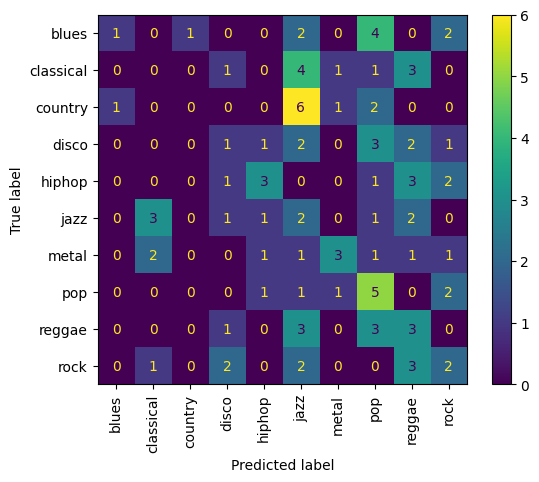

In [59]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_val, y_pred, xticks_rotation="vertical")

In [74]:
for i, g in enumerate(GENRES):
    TP = cm[i, i]
    FN = np.sum(cm[i, :]) - TP # Row - TP
    FP = np.sum(cm[:, i]) - TP # Col - TP
    print(f"{g}:")
    print(f"TP: {TP}, FN: {FN}, FP: {FP}\n")

blues:
TP: 1, FN: 9, FP: 1

classical:
TP: 0, FN: 10, FP: 6

country:
TP: 0, FN: 10, FP: 1

disco:
TP: 1, FN: 9, FP: 6

hiphop:
TP: 3, FN: 7, FP: 4

jazz:
TP: 2, FN: 8, FP: 21

metal:
TP: 3, FN: 7, FP: 3

pop:
TP: 5, FN: 5, FP: 16

reggae:
TP: 3, FN: 7, FP: 14

rock:
TP: 2, FN: 8, FP: 8

